# Juneau Icefield point simulation sites

These maps show MLD4, CLFG, and the five radar simulation sites. All three use the same
site-focused view in WGS 84 / UTM zone 8N. Run from the repository root or
`jif_domain/` using the JIF snow modeling environment.

The satellite map caches Esri World Imagery under `data/basemaps/`. The HRRR-AK
maps read a single local GRIB2 file. All three maps export PNGs to `figures/`.

In [1]:
import hashlib
import io
import json
import os
from pathlib import Path
import sys
from urllib.parse import urlencode
from urllib.request import urlopen

import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
import pygrib
from pyproj import CRS, Transformer

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'jif_domain').is_dir())
FIGURES = ROOT / 'figures'
CACHE = ROOT / 'data/basemaps'
FIGURES.mkdir(exist_ok=True)

sys.path.insert(0, str(ROOT / 'sites/radar_sites/scripts'))
from prepare_radar_site_forcing import MODEL_ROOT, PERIOD, SITES

MODEL_SITES = Path(os.environ.get('JIF_MODEL_SITES', MODEL_ROOT))
GRIB = Path(os.environ.get(
    'JIF_GRIB',
    '/hdd/snow_hydrology/hrrrak/icefield_domain/f567/WY2026/'
    'hrrr.20260525/hrrr.t12z.wrfsfcf06.ak.grib2',
))
UTM = 32608
to_utm = Transformer.from_crs(4326, UTM, always_xy=True)

## Simulation coordinates

MLD4 uses the coordinates in its WY2020–WY2025 forcing notebook. Radar
coordinates come from the prepared raw-forcing metadata for each simulation,
including the established TKG4 point. CLFG is read from `sites/clfg/site_info.txt`.
Set `JIF_MODEL_SITES` if the prepared radar inputs are stored outside the default model directory.

Glacier labels mark general locations using the
[U.S. Census Bureau glacier inventory](https://tigerweb.geo.census.gov/tigerwebmain/Files/acs24/tigerweb_acs24_glaciers_us.html)
and the [Alaska State Library glacier index](https://library.alaska.gov/asp/alaska_glaciers.HTML).


In [2]:
rows = [('MLD4', 58.85892, -134.15728, 'MLD4')]
for site in SITES:
    stem = f'hrrrak_{site}_{PERIOD}'
    metadata = json.loads(
        (MODEL_SITES / site / 'input' / f'hrrrak_{PERIOD}' / f'{stem}.json').read_text()
    )
    rows.append((site.upper(), metadata['latitude'], metadata['longitude'], 'Radar sites'))

clfg = dict(line.split(': ', 1) for line in
            (ROOT / 'sites/clfg/site_info.txt').read_text().splitlines() if line.strip())
lat, lon = (float(clfg[key].rsplit('(', 1)[1].rstrip(')')) for key in ('Latitude', 'Longitude'))
rows.append(('CLFG', lat, lon, 'CLFG'))

sites = pd.DataFrame(rows, columns=['site', 'latitude', 'longitude', 'group'])
east, north = to_utm.transform(sites.longitude.to_numpy(), sites.latitude.to_numpy())
sites = sites.assign(easting_km=east / 1000, northing_km=north / 1000)

# Use a common view with 12 km of space beyond the outermost points.
padding = 12
west = np.floor(sites.easting_km.min() - padding)
east = np.ceil(sites.easting_km.max() + padding)
south = np.floor(sites.northing_km.min() - padding)
north = np.ceil(sites.northing_km.max() + padding)
sites.round(6)

,site,latitude,longitude,group,easting_km,northing_km
0,MLD4,58.858920,-134.157280,MLD4,548.613301,6524.648850
1,TKG2,58.688654,-134.382797,Radar sites,535.779000,6505.549000
2,TKG3,58.656386,-134.277751,Radar sites,541.907000,6502.017000
3,C161,58.632957,-134.418588,Radar sites,533.758000,6499.329000
4,TKG4,58.634470,-134.237080,Radar sites,544.294565,6499.603015
5,DG1,58.617588,-134.130047,Radar sites,550.533000,6497.799000
6,CLFG,58.494719,-134.541750,CLFG,526.712068,6483.882033


In [3]:
styles = {
    'MLD4': ('o', '#56b4e9'),
    'Radar sites': ('^', '#f5cb59'),
    'CLFG': ('D', '#ed8ec0'),
}
offsets = {'TKG3': (-7, 8), 'TKG4': (7, -9), 'CLFG': (7, -8)}

glacier_labels = {
    'Mendenhall Glacier': (-134.538629, 58.5052512),
    'Herbert Glacier': (-(134 + 36/60 + 30/3600), 58 + 34/60 + 9/3600),
    'Taku Glacier': (-134.1618566, 58.5744301),
}

def plot_sites(ax):
    for name, (longitude, latitude) in glacier_labels.items():
        x_m, y_m = to_utm.transform(longitude, latitude)
        ax.text(x_m / 1000, y_m / 1000, name, ha='center', va='center',
                color='white', fontsize=9, weight='bold', zorder=4,
                path_effects=[pe.withStroke(linewidth=2.6, foreground='#263441')])
    for group, (marker, color) in styles.items():
        points = sites[sites.group == group]
        ax.scatter(points.easting_km, points.northing_km, marker=marker, s=80,
                   color=color, edgecolor='#15212c', linewidth=1, label=group, zorder=4)
    for site in sites.itertuples():
        dx, dy = offsets.get(site.site, (7, 7))
        ax.annotate(site.site, (site.easting_km, site.northing_km),
                    xytext=(dx, dy), textcoords='offset points',
                    ha='left' if dx > 0 else 'right', va='bottom' if dy > 0 else 'top',
                    fontsize=9, weight='bold', color='#15212c', zorder=5,
                    bbox=dict(boxstyle='round,pad=0.23', fc='white', ec='none', alpha=0.92))
    ax.set(xlim=(west, east), ylim=(south, north), aspect='equal',
           xlabel='UTM zone 8N easting (km)', ylabel='UTM zone 8N northing (km)')
    ax.ticklabel_format(useOffset=False, style='plain')
    ax.legend(loc='upper left', framealpha=0.95)

## Satellite imagery

[Esri World Imagery](https://services.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer)
is requested in UTM zone 8N. The cached image uses the extent returned by the service.
The first run requires internet access.

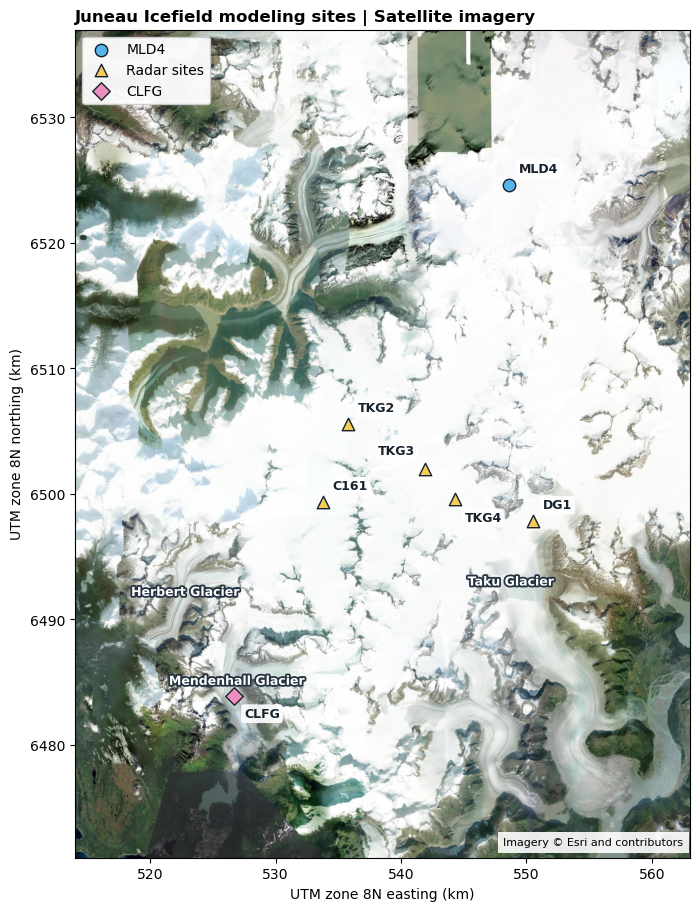

In [4]:
service = 'https://services.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer'
params = dict(
    bbox=','.join(str(int(km * 1000)) for km in (west, south, east, north)),
    bboxSR=UTM, imageSR=UTM, size=f'{int((east-west)*24)},{int((north-south)*24)}',
    format='jpg', f='json',
)
cache_key = hashlib.sha256(urlencode(params).encode()).hexdigest()[:16]
image_path = CACHE / f'esri_{cache_key}.jpg'
metadata_path = CACHE / f'esri_{cache_key}.json'
if not (image_path.is_file() and metadata_path.is_file()):
    with urlopen(f'{service}/export?{urlencode(params)}', timeout=60) as response:
        metadata = json.load(response)
    if 'error' in metadata:
        raise RuntimeError(f'Esri World Imagery export failed: {metadata["error"]}')
    with urlopen(metadata['href'], timeout=60) as response:
        image_bytes = response.read()
    with Image.open(io.BytesIO(image_bytes)) as downloaded:
        downloaded.verify()
    CACHE.mkdir(parents=True, exist_ok=True)
    image_path.write_bytes(image_bytes)
    metadata_path.write_text(json.dumps(metadata, indent=2))

bounds = json.loads(metadata_path.read_text())['extent']
image_extent = [bounds[key] / 1000 for key in ('xmin', 'xmax', 'ymin', 'ymax')]
with Image.open(image_path) as cached:
    imagery = np.asarray(cached.convert('RGB'))

fig, ax = plt.subplots(figsize=(8, 9), layout='constrained')
ax.imshow(imagery, extent=image_extent, origin='upper')
plot_sites(ax)
ax.set_title('Juneau Icefield modeling sites | Satellite imagery', loc='left', weight='bold')
ax.text(0.99, 0.015, 'Imagery © Esri and contributors', transform=ax.transAxes,
        ha='right', fontsize=8, bbox=dict(fc='white', ec='none', alpha=0.9))
fig.savefig(FIGURES / 'jif_modeling_sites_satellite.png', dpi=180)
plt.show()

## HRRR-AK 2 m air temperature

The default snapshot is valid at 18:00 UTC on May 25, 2026, the date of the CLFG
snow-depth observation. Set `JIF_GRIB` to use another local HRRR-AK file. Cell
corners are calculated at half-grid offsets in the native polar stereographic
projection and then transformed to UTM. The linework traces native grid cells.

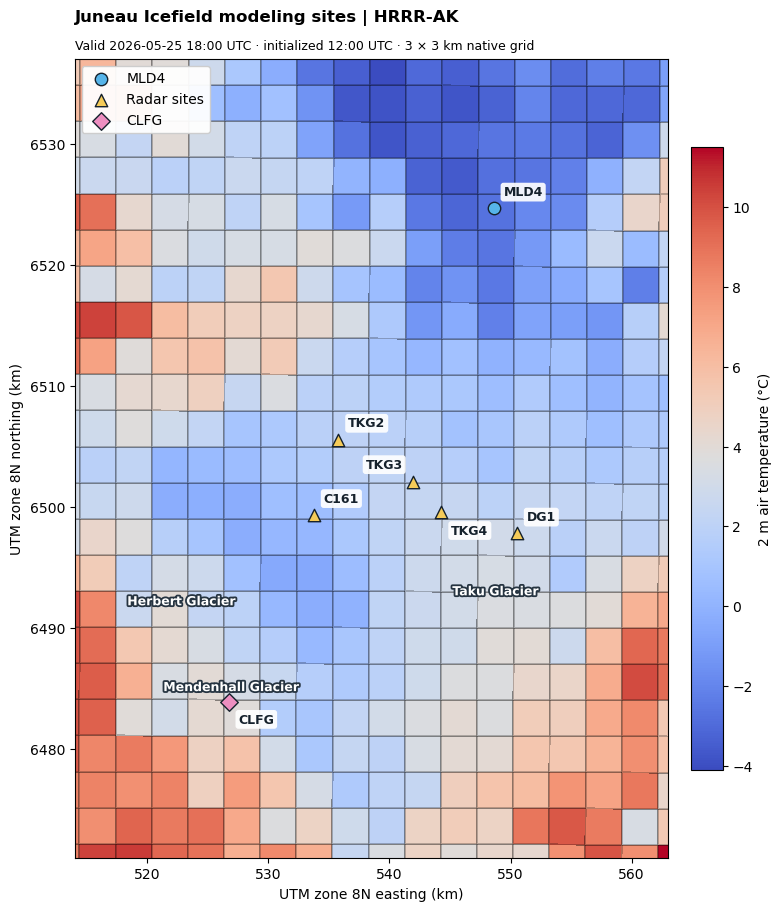

In [5]:
if not GRIB.is_file():
    raise FileNotFoundError(f'{GRIB} is missing. Set JIF_GRIB to a local HRRR-AK GRIB2 file.')

with pygrib.open(str(GRIB)) as fields:
    temperature_field, = fields.select(shortName='2t', typeOfLevel='heightAboveGround', level=2)
    temperature = temperature_field.values - 273.15
    lat, lon = temperature_field.latlons()
    native = CRS.from_dict(temperature_field.projparams)
    dx, dy = temperature_field['DxInMetres'], temperature_field['DyInMetres']
    initialized, valid = temperature_field.analDate, temperature_field.validDate

to_native = Transformer.from_crs(4326, native, always_xy=True)
native_to_utm = Transformer.from_crs(native, UTM, always_xy=True)
center_x, center_y = to_native.transform(lon, lat)
ny, nx = temperature.shape
x = center_x[0, 0] + np.arange(nx) * np.copysign(dx, center_x[0, -1] - center_x[0, 0])
y = center_y[0, 0] + np.arange(ny) * np.copysign(dy, center_y[-1, 0] - center_y[0, 0])
if not (np.allclose(center_x, x[None, :], atol=2, rtol=0)
        and np.allclose(center_y, y[:, None], atol=2, rtol=0)):
    raise ValueError('Decoded coordinates do not match a regular native HRRR-AK grid.')

x_edges = x[0] + (np.arange(nx + 1) - 0.5) * np.copysign(dx, x[-1] - x[0])
y_edges = y[0] + (np.arange(ny + 1) - 0.5) * np.copysign(dy, y[-1] - y[0])
grid_x, grid_y = native_to_utm.transform(*np.meshgrid(x_edges, y_edges))
grid_x, grid_y = grid_x / 1000, grid_y / 1000

# Scale the colors to cells whose corner bounds intersect the map.
corners_x = [grid_x[:-1, :-1], grid_x[1:, :-1], grid_x[:-1, 1:], grid_x[1:, 1:]]
corners_y = [grid_y[:-1, :-1], grid_y[1:, :-1], grid_y[:-1, 1:], grid_y[1:, 1:]]
in_view = (
    (np.min(corners_x, axis=0) < east) & (np.max(corners_x, axis=0) > west)
    & (np.min(corners_y, axis=0) < north) & (np.max(corners_y, axis=0) > south)
)
visible = np.ma.masked_invalid(temperature[in_view])
if visible.count() == 0:
    raise ValueError('The selected GRIB has no valid temperatures in the map extent.')

fig, ax = plt.subplots(figsize=(9, 9), layout='constrained')
mesh = ax.pcolormesh(grid_x, grid_y, temperature, shading='flat', cmap='coolwarm',
                     edgecolors=(0, 0, 0, 0.24), linewidth=0.35,
                     vmin=visible.min(), vmax=visible.max())
plot_sites(ax)
fig.colorbar(mesh, ax=ax, shrink=0.78, pad=0.03, label='2 m air temperature (°C)')
ax.set_title('Juneau Icefield modeling sites | HRRR-AK', loc='left', weight='bold', pad=27)
ax.text(0, 1.012, f'Valid {valid:%Y-%m-%d %H:%M} UTC · initialized {initialized:%H:%M} UTC'
        f' · {dx/1000:g} × {dy/1000:g} km native grid', transform=ax.transAxes, fontsize=9)
fig.savefig(FIGURES / 'jif_modeling_sites_hrrrak.png', dpi=180)
plt.show()

## Satellite imagery with HRRR-AK overlay

The translucent temperature layer uses the same forecast, cell boundaries, and
color limits as the HRRR-AK map above.

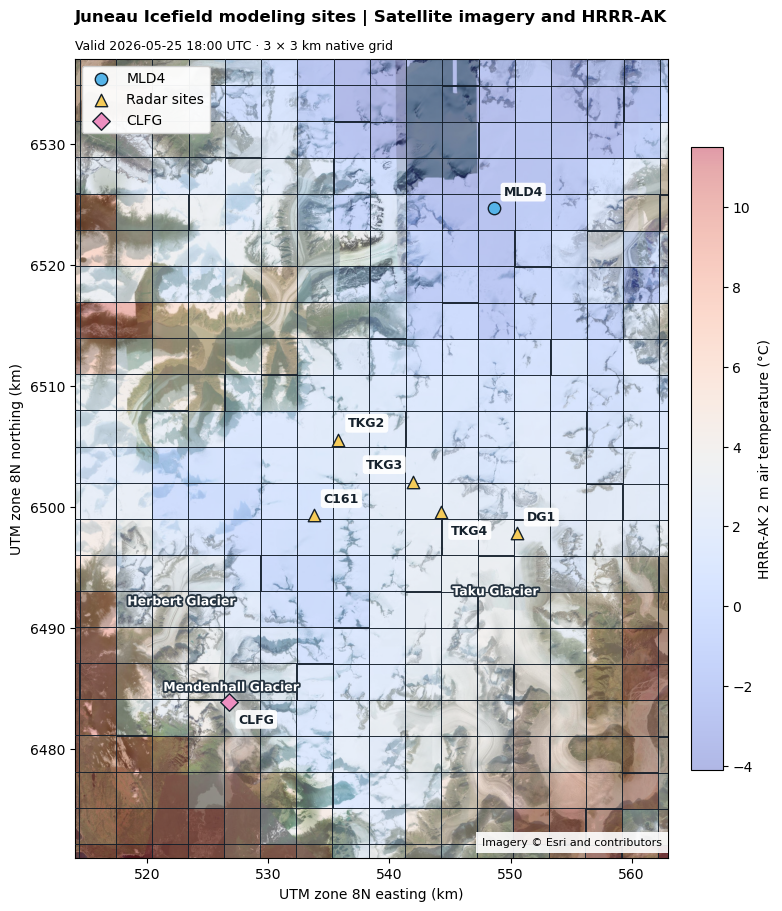

In [6]:
fig, ax = plt.subplots(figsize=(9, 9), layout='constrained')
ax.imshow(imagery, extent=image_extent, origin='upper')
mesh = ax.pcolormesh(grid_x, grid_y, temperature, shading='flat', cmap='coolwarm',
                     alpha=0.40, vmin=visible.min(), vmax=visible.max(), zorder=2)

# Draw cell boundaries separately so they stay visible over bright imagery.
outlines = ax.pcolormesh(grid_x, grid_y, temperature, shading='flat',
                         edgecolors=(0.08, 0.12, 0.17, 0.72), linewidth=0.7, zorder=3)
outlines.set_array(None)
outlines.set_facecolor('none')

plot_sites(ax)
fig.colorbar(mesh, ax=ax, shrink=0.78, pad=0.03, label='HRRR-AK 2 m air temperature (°C)')
ax.set_title('Juneau Icefield modeling sites | Satellite imagery and HRRR-AK',
             loc='left', weight='bold', pad=27)
ax.text(0, 1.012, f'Valid {valid:%Y-%m-%d %H:%M} UTC'
        f' · {dx/1000:g} × {dy/1000:g} km native grid', transform=ax.transAxes, fontsize=9)
ax.text(0.99, 0.015, 'Imagery © Esri and contributors', transform=ax.transAxes,
        ha='right', fontsize=8, bbox=dict(fc='white', ec='none', alpha=0.9), zorder=6)
fig.savefig(FIGURES / 'jif_modeling_sites_satellite_hrrrak.png', dpi=180)
plt.show()